# Triggering Conditions and Scenario-Based Evaluation

**Module 04 · SOTIF (ISO 21448)** · Notebook 2 of 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/04_SOTIF_ISO21448/02_triggering_conditions_and_scenarios.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [01 · SOTIF fundamentals](01_sotif_fundamentals.ipynb); [01/04 · Object detection](../01_Perception/04_object_detection.ipynb) | ISO 21448:2022, ISO 34502:2022, ISO 34503:2023 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- Build a triggering-condition catalogue structured by the PEGASUS **6-layer model** and keep out-of-scope causes apart
- Link triggering conditions to **functional insufficiencies** (specification vs performance)
- **Measure** a performance insufficiency of a real camera detector on real KITTI frames under physically based fog,
  low light and lens dirt, and locate the **triggering-condition boundary** with confidence intervals
- Turn the measurement into an industry-style **triggering-condition table** with measures and an **ODD restriction**
- Use the scenario abstraction levels **functional → logical → concrete** and distinguish a scenario from the **ODD** (ISO 34503:2023)
- Describe the **ISO 34502:2022** scenario-based safety evaluation framework and the role of **ASAM OpenSCENARIO / OpenODD**
- Generate a scenario space, measure **n-wise coverage** and build a **pairwise test set** in Python
- Explain what coverage of a discretised space does — and does not — say about residual risk

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D
from avsafety import sotif

import os
from itertools import combinations, product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from scipy import ndimage, optimize, stats
from IPython.display import display

rng = np.random.default_rng(42)
OI = {'orange': '#E69F00', 'sky': '#56B4E9', 'green': '#009E73', 'yellow': '#F0E442',
      'blue': '#0072B2', 'vermillion': '#D55E00', 'purple': '#CC79A7', 'grey': '#999999', 'black': '#000000'}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
print("Setup complete.")

Setup complete.


**Data and licence.** Section 5 uses 30 frames of the KITTI object-detection training set (camera image, Velodyne
HDL-64E scan, labels and calibration), fetched on demand by `avsafety.data` and cached locally, and a COCO-pretrained
detector from torchvision. KITTI is licensed CC BY-NC-SA 3.0 (non-commercial use); its frames were recorded in and
around Karlsruhe in daylight and dry weather — which is exactly why fog and darkness have to be *added* to study them.

In [2]:
print(D.attribution('KITTI'))

Data: KITTI Vision Benchmark Suite (Geiger et al., CVPR 2012 / IJRR 2013), CC BY-NC-SA 3.0, https://www.cvlibs.net/datasets/kitti/


## 1. Recap: where triggering conditions sit

ISO 21448:2022 addresses hazards caused by **functional insufficiencies** — insufficiencies of specification and
performance insufficiencies — of a function that is working as designed. A **triggering condition** is a specific
condition of a scenario that activates such an insufficiency:

```
Triggering condition → activates functional insufficiency → output insufficiency
   → propagates to hazardous behaviour → in a scenario without sufficient controllability → harm
```

> "The system is not broken — it just cannot handle this scenario."

Unlike ISO 26262, which handles random hardware faults and systematic hardware/software faults, SOTIF analyses the
**scenarios** in which a fault-free function is insufficient. This notebook is about building those scenarios
systematically. Areas 1–4 were introduced in [Notebook 01](01_sotif_fundamentals.ipynb): Area 1 known/not hazardous,
Area 2 known/hazardous, **Area 3 unknown/hazardous**, Area 4 unknown/not hazardous.

## 2. Scenario vocabulary

**Operational design domain (ODD)** — the operating conditions under which a function is designed to work
(SAE J3016:2021). **ISO 34503:2023** specifies a hierarchical ODD taxonomy with three top-level attribute groups:

| ISO 34503 top-level attribute | Contents (examples) |
|---|---|
| **Scenery** | Non-movable elements: road type and geometry, lane markings, junctions, signs, bridges, tunnels, roadside structures |
| **Environmental conditions** | Weather (rain, snow, wind, temperature), particulates (fog, dust), illumination (day, night, low sun), connectivity |
| **Dynamic elements** | Movable objects and actors: other traffic participants, their density and behaviour, and the subject vehicle itself (e.g. speed) |

ISO 34503 is aimed mainly at Level 3 and Level 4 automated driving systems. **ASAM OpenODD 1.0.0** (released April 2025)
provides machine-readable ODD formats (YAML, tabular, OpenSCENARIO DSL) so that an ODD can be checked against
scenarios and data automatically.

A **scenario** is a temporal sequence of scenes with actions and events of the participants. An ODD says *where and
when* the function may operate; scenarios are *what happens* there. A scenario can lie inside the ODD, outside it, or
cross its boundary (an **ODD exit**, which the function must detect and handle).

**Abstraction levels** (Menzel, Bagschik & Maurer, 2018):

| Level | Description | Example |
|---|---|---|
| **Functional** | Linguistic description for experts | "On an urban road, a pedestrian crosses in front of the vehicle, possibly hidden by a parked car" |
| **Logical** | Parameters with **ranges** (and possibly distributions) | ego speed 30–50 km/h; illumination ∈ {day, dusk, night lit}; occlusion ∈ {none, parked car} |
| **Concrete** | One fixed **value** per parameter — executable in a simulator or on a test track | ego 40 km/h, dusk, light rain, child, running, occluded |

One logical scenario defines a **scenario space**; concrete scenarios are samples from it.

## 3. Structuring triggering conditions: the 6-layer model

The **6-layer model** from the German PEGASUS project — formalised for urban traffic by Scholtes et al. (2021) — is
a widely used structure for describing the environment of a scenario. Using it for a triggering-condition catalogue
makes gaps visible.

| Layer | Content | Triggering-condition examples (camera/LiDAR perception) |
|---|---|---|
| L1 Road network & traffic guidance | Road geometry, markings, signs | Faded or contradictory markings, non-standard signs, sharp curves |
| L2 Roadside structures | Buildings, barriers, vegetation | Parked-vehicle rows, hedges hiding pedestrians, reflective façades |
| L3 Temporary modifications of L1/L2 | Construction zones, temporary markings | Yellow temporary lines over white ones, shifted lanes |
| L4 Dynamic objects | Road users, their types and behaviour | Child running out, wheelchair user, animal, wrong-way driver |
| L5 Environmental conditions | Weather, lighting, road surface | Heavy rain, fog, low sun, tunnel exit, wet reflective road |
| L6 Digital information | V2X, maps, digital signals | Outdated HD map after re-routing, missing V2X message |

**Mapping to ISO 34503 (approximate):** scenery ≈ L1–L3, environmental conditions ≈ L5 (connectivity ≈ L6),
dynamic elements ≈ L4.

Two further groups matter for SOTIF but sit outside the 6 layers: **external disturbances of sensors** (dirt, spray,
ice on the sensor cover) and **driver behaviour, including reasonably foreseeable misuse**.

Things that look like triggering conditions but are **not**:

- *Hardware degradation, EMI, memory overflow, data corruption, timeouts* → E/E faults → **ISO 26262**
- *Adversarial patterns, spoofing* → attacks → **ISO/SAE 21434**
- *"Out-of-distribution input", "domain shift", "rare class"* → properties of the **system's** training-data coverage,
  i.e. **functional (performance) insufficiencies**, not conditions of the scenario.

In [3]:
# Triggering-condition catalogue, structured by the 6-layer model (+ sensor exposure and driver behaviour)
triggering_conditions = {
    'L1 Road network': ['Faded lane markings', 'Contradictory markings', 'Non-standard traffic sign', 'Sharp curve'],
    'L2 Roadside structures': ['Row of parked vehicles', 'Hedge at the kerb', 'Reflective glass facade'],
    'L3 Temporary modifications': ['Construction zone with shifted lanes', 'Temporary yellow markings', 'Mobile traffic light'],
    'L4 Dynamic objects': ['Child running out', 'Wheelchair user', 'Person carrying a large object',
                           'Animal on road', 'Cyclist emerging from side street', 'Wrong-way driver'],
    'L5 Environment': ['Heavy rain', 'Dense fog', 'Low sun in field of view', 'Tunnel exit (glare)',
                       'Night, unlit road', 'Wet road with reflections', 'Snowfall'],
    'L6 Digital information': ['Outdated HD map', 'Missing V2X message'],
    'Sensor exposure': ['Dirt or mud on lens', 'Water spray from truck', 'Ice on sensor cover',
                        'Retro-reflector saturating LiDAR'],
    'Driver behaviour / misuse': ['Hands off wheel for long periods (L2)', 'Driver asleep or reading',
                                  'Activation outside the ODD'],
}

# Causes that belong to other standards — kept separate on purpose
out_of_scope = {
    'ISO 26262 (E/E faults)': ['Hardware degradation', 'EMI', 'Memory overflow', 'Data corruption', 'Timeout'],
    'ISO/SAE 21434 (security)': ['Adversarial patch', 'LiDAR spoofing', 'GNSS spoofing'],
}

tc_df = pd.DataFrame([{'TC-ID': f'TC-{i+1:02d}', 'Group': g, 'Triggering condition': c}
                      for i, (g, c) in enumerate((g, c) for g, cs in triggering_conditions.items() for c in cs)])
print(f"Triggering conditions in catalogue: {len(tc_df)}")
display(tc_df['Group'].value_counts().rename('count').to_frame())
print("Kept out of the SOTIF catalogue:",
      "; ".join(f"{k}: {len(v)} items" for k, v in out_of_scope.items()))

Triggering conditions in catalogue: 32


,count
Group,
L5 Environment,7
L4 Dynamic objects,6
L1 Road network,4
Sensor exposure,4
L2 Roadside structures,3
L3 Temporary modifications,3
Driver behaviour / misuse,3
L6 Digital information,2


Kept out of the SOTIF catalogue: ISO 26262 (E/E faults): 5 items; ISO/SAE 21434 (security): 3 items


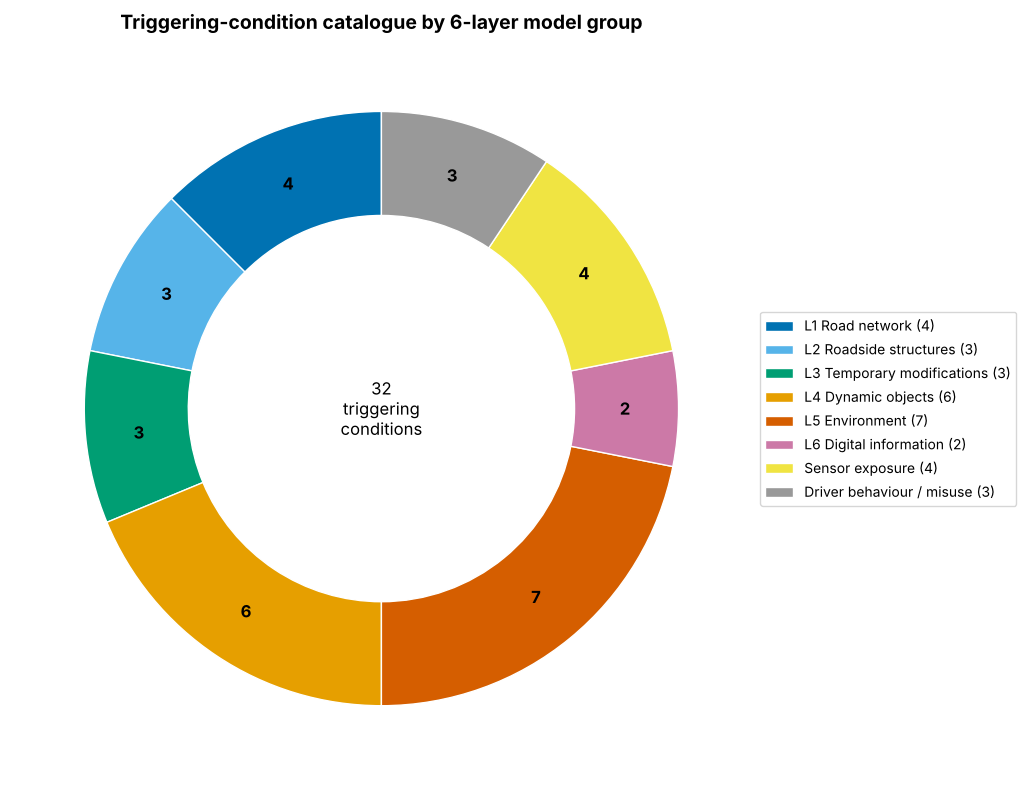

In [4]:
def visualize_triggering_conditions():
    """Nested donut: groups (inner ring) and number of triggering conditions per group (outer ring)."""
    palette = [OI['blue'], OI['sky'], OI['green'], OI['orange'], OI['vermillion'], OI['purple'],
               OI['yellow'], OI['grey']]
    groups = list(triggering_conditions)
    sizes = [len(triggering_conditions[g]) for g in groups]
    fig, ax = plt.subplots(figsize=(11, 8))
    wedges, _ = ax.pie(sizes, radius=1.0, colors=palette, startangle=90,
                       wedgeprops=dict(width=0.35, edgecolor='white'))
    for w, n in zip(wedges, sizes):
        ang = np.deg2rad((w.theta2 + w.theta1) / 2)
        ax.text(0.82 * np.cos(ang), 0.82 * np.sin(ang), str(n), ha='center', va='center',
                fontsize=12, fontweight='bold')
    ax.legend(wedges, [f'{g} ({n})' for g, n in zip(groups, sizes)], loc='center left',
              bbox_to_anchor=(1.0, 0.5), fontsize=10)
    ax.text(0, 0, f'{sum(sizes)}\ntriggering\nconditions', ha='center', va='center', fontsize=12)
    ax.set_title('Triggering-condition catalogue by 6-layer model group', fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()

visualize_triggering_conditions()

## 4. Functional insufficiencies

ISO 21448:2022 knows two types: **insufficiency of specification** and **performance insufficiency**. The table
below links each insufficiency to the triggering conditions that activate it and to the resulting output
insufficiency. Training-data coverage problems ("OOD input", "rare class") appear here — as performance
insufficiencies of the algorithm.

Note on FI-05: "the ODD excludes construction zones" is a design decision, not an insufficiency. The insufficiency is
that the **specification does not define behaviour when approaching** an excluded construction zone (ODD exit).

In [5]:
functional_insufficiencies = pd.DataFrame({
    'FI-ID': ['FI-01', 'FI-02', 'FI-03', 'FI-04', 'FI-05', 'FI-06', 'FI-07', 'FI-08'],
    'ISO 21448 type': ['Performance', 'Performance', 'Performance', 'Performance', 'Specification',
                       'Performance', 'Performance', 'Specification'],
    'Element': ['Camera', 'LiDAR', 'Detector (training-data coverage)', 'Tracker', 'Function specification',
                'Sensor fusion', 'Detector (training-data coverage)', 'Function specification'],
    'Description': [
        'Limited dynamic range of the camera',
        'Reduced range and spurious returns in heavy rain/spray',
        'Low recall for under-represented road-user types',
        'Tracks lost after long occlusion',
        'No specified behaviour on approach to a construction zone (ODD exit)',
        'Misassociation when objects are close together',
        'Low recall for unusual poses (crouching, carrying objects)',
        'No requirement for pedestrians emerging at short time-to-collision',
    ],
    'Activated by': ['Low sun in field of view; Tunnel exit (glare)', 'Heavy rain; Water spray from truck',
                     'Wheelchair user; Animal on road', 'Row of parked vehicles', 'Construction zone with shifted lanes',
                     'Cyclist emerging from side street', 'Person carrying a large object', 'Child running out'],
    'Output insufficiency': ['Missed detection', 'Reduced detection range; false positives',
                             'Missed or misclassified object', 'Late re-detection', 'Undefined vehicle behaviour',
                             'Wrong object position/velocity', 'Missed detection', 'Braking starts too late'],
})
display(functional_insufficiencies)

# Consistency check: every activating TC must exist in the catalogue
all_tcs = set(tc_df['Triggering condition'])
missing = {t.strip() for cell in functional_insufficiencies['Activated by'] for t in cell.split(';')} - all_tcs
types = functional_insufficiencies['ISO 21448 type'].value_counts()
print(f"Text summary: {len(functional_insufficiencies)} functional insufficiencies "
      f"({', '.join(f'{k}: {v}' for k, v in types.items())}); "
      f"triggering conditions referenced but missing from the catalogue: {sorted(missing) if missing else 'none'}")

,FI-ID,ISO 21448 type,Element,Description,Activated by,Output insufficiency
0,FI-01,Performance,Camera,Limited dynamic range of the camera,Low sun in field of view; Tunnel exit (glare),Missed detection
1,FI-02,Performance,LiDAR,Reduced range and spurious returns in heavy ra...,Heavy rain; Water spray from truck,Reduced detection range; false positives
2,FI-03,Performance,Detector (training-data coverage),Low recall for under-represented road-user types,Wheelchair user; Animal on road,Missed or misclassified object
3,FI-04,Performance,Tracker,Tracks lost after long occlusion,Row of parked vehicles,Late re-detection
4,FI-05,Specification,Function specification,No specified behaviour on approach to a constr...,Construction zone with shifted lanes,Undefined vehicle behaviour
5,FI-06,Performance,Sensor fusion,Misassociation when objects are close together,Cyclist emerging from side street,Wrong object position/velocity
6,FI-07,Performance,Detector (training-data coverage),"Low recall for unusual poses (crouching, carry...",Person carrying a large object,Missed detection
7,FI-08,Specification,Function specification,No requirement for pedestrians emerging at sho...,Child running out,Braking starts too late


Text summary: 8 functional insufficiencies (Performance: 6, Specification: 2); triggering conditions referenced but missing from the catalogue: none


## 5. Measuring performance insufficiencies on real data

A catalogue lists *candidate* triggering conditions. ISO 21448 asks for evidence of how strongly each one degrades
the function (clauses 7 and 10). For a perception component the evidence is a measurement: run the real component on
real sensor data, vary one condition at a time, and find where its performance falls below a **derived
requirement**. That point is a **triggering-condition boundary**.

**Set-up used here.**

| Element | Choice | Why |
|---|---|---|
| Function | Pedestrian AEB, urban sub-scope ≤ 60 km/h (the course's recurring AEB item; SG-02 *avoid omission of AEB deceleration*) | AEB needs the pedestrian before the stopping distance is used up |
| Component under test | `fasterrcnn_mobilenet_v3_large_fpn`, COCO-pretrained (torchvision), CPU | A real, small camera detector; not trained on KITTI and not a product |
| Data | 30 KITTI frames chosen deterministically for having ≥ 3 visible pedestrians within 40 m | Enough pedestrians (≈ 150) for confidence intervals |
| Metric | Per-frame recall of KITTI-labelled pedestrians (box IoU ≥ 0.5, score ≥ 0.3) | Misses are what SG-02 is about |
| Conditions | Clear air and fog at 5 visibilities, low light with sensor noise (2 levels), lens dirt (1 level) | L5 environment and *sensor exposure* groups of the catalogue |

**AEB-relevant range.** The pedestrian must be detected at least one stopping distance ahead. At the upper end of
the urban sub-scope (60 km/h) with 0.5 s from detection to full braking and 6 m/s² on a road that may be damp in
fog, `avsafety.sotif.stopping_distance` gives the range computed below. The requirement is a **per-frame** recall of
65 %: the AEB function confirms a pedestrian over several frames before braking, so a single-frame miss is not yet a
missed brake (but consecutive frames are correlated, so the margin has to be shown, not assumed). The value is
**illustrative**: in a real project it is derived from the vehicle-level acceptance criterion through the AEB architecture (radar
fusion, confirmation logic), as discussed in [Notebook 04](04_simulation_based_validation.ipynb).

In [6]:
FRAMES = [518, 764, 961, 1357, 1693, 1988, 2160, 2379, 2595, 2775, 2966, 3438, 3560, 3763, 4235,
          4442, 4704, 4924, 5037, 5278, 5524, 5692, 5980, 6176, 6422, 6552, 6761, 6925, 7189, 7464]

V_URBAN_KMH, T_REACT_S, DECEL = 60, 0.5, 6.0
AEB_RANGE_M = float(np.ceil(sotif.stopping_distance(V_URBAN_KMH / 3.6, T_REACT_S, DECEL)))
REQ_RECALL = 0.65        # illustrative derived requirement: per-frame pedestrian recall within AEB_RANGE_M
SCORE_THR, IOU_THR = 0.3, 0.5     # detector operating point; box overlap for a match

VISIBILITIES = [np.inf, 300, 150, 80, 40, 25]       # m; inf = clear air
LIGHT_FACTORS = [1 / 64, 1 / 256]                     # scene light relative to the KITTI daylight exposure
DIRT_COVERAGE = 0.25                                  # fraction of the image covered by lens dirt

print(f"AEB-relevant range: stopping distance at {V_URBAN_KMH} km/h = "
      f"{sotif.stopping_distance(V_URBAN_KMH / 3.6, T_REACT_S, DECEL):.1f} m → evaluate pedestrians within {AEB_RANGE_M:.0f} m")
print(f"Derived requirement (illustrative): pedestrian recall ≥ {REQ_RECALL:.0%} within {AEB_RANGE_M:.0f} m")

AEB-relevant range: stopping distance at 60 km/h = 31.5 m → evaluate pedestrians within 32 m
Derived requirement (illustrative): pedestrian recall ≥ 65% within 32 m


### 5.1 Physically based fog from LiDAR depth

Fog does not simply lower contrast everywhere: light from an object at distance $d$ is attenuated, and light scattered
by the droplets (*airlight*) is added. **Koschmieder's law** (Koschmieder, 1924), used for synthetic fog by Sakaridis,
Dai and Van Gool (2018) to create *Foggy Cityscapes*, describes this for homogeneous fog:

$$I(x) = J(x)\,t(x) + A\,\bigl(1 - t(x)\bigr), \qquad t(x) = e^{-\beta\, d(x)},$$

with $J$ the clear image, $A$ the atmospheric light, $\beta$ the extinction coefficient and $d(x)$ the distance of the
scene point seen in pixel $x$. The **meteorological visibility** is the distance at which the contrast of a dark object
against the horizon drops to 5 %: $V = -\ln(0.05)/\beta \approx 3/\beta$. Meteorology calls it fog below 1 km; German
traffic law (§ 3 (1) StVO) caps speed at 50 km/h when fog, snow or rain reduce visibility below 50 m.

The physics needs $d(x)$ for every pixel. KITTI has no dense depth, but it has a calibrated LiDAR: project the scan into
the image, keep the nearest return per 4 × 4-pixel cell, fill gaps with the nearest return (pixels above the LiDAR's
upper beam take the depth of the highest return in their column — a vertical-surface assumption that mainly affects
sky and façades, not road users), and smooth with a median filter. The model is applied in linear RGB with a uniform
grey atmospheric light $A = 0.8$.

In [7]:
def srgb_to_lin(x):
    return np.where(x <= 0.04045, x / 12.92, ((x + 0.055) / 1.055) ** 2.4)

def lin_to_srgb(x):
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * x ** (1 / 2.4) - 0.055)

def dense_range(frame, cell=4):
    """Per-pixel distance (m) from the projected LiDAR scan: nearest return per cell, gaps filled, smoothed."""
    H, W = frame.image.shape[:2]
    rect = frame.velo_to_rect(frame.points)
    rect = rect[rect[:, 2] > 1.0]                                  # in front of the camera
    uv = frame.rect_to_image(rect)
    dist = np.linalg.norm(rect, axis=1)                            # distance along the line of sight
    ok = (uv[:, 0] >= 0) & (uv[:, 0] < W) & (uv[:, 1] >= 0) & (uv[:, 1] < H)
    gh, gw = -(-H // cell), -(-W // cell)
    grid = np.full((gh, gw), np.inf)
    np.minimum.at(grid, ((uv[ok, 1] // cell).astype(int), (uv[ok, 0] // cell).astype(int)), dist[ok])
    for c in range(gw):                                            # above the top beam: copy upwards
        rows = np.flatnonzero(np.isfinite(grid[:, c]))
        if len(rows):
            grid[:rows[0], c] = grid[rows[0], c]
    idx = ndimage.distance_transform_edt(~np.isfinite(grid), return_distances=False, return_indices=True)
    grid = ndimage.median_filter(grid[tuple(idx)], size=5)
    return ndimage.zoom(grid, (H / gh, W / gw), order=1)[:H, :W]

def add_fog(img, dist, visibility_m, airlight=0.8):
    """Koschmieder: I = J t + A (1 - t), t = exp(-beta d), beta = -ln(0.05) / V."""
    if not np.isfinite(visibility_m):
        return img
    t = np.exp(np.log(0.05) / visibility_m * dist)[..., None]
    out = srgb_to_lin(img / 255.0) * t + airlight * (1 - t)
    return (lin_to_srgb(out) * 255 + 0.5).astype(np.uint8)

frames = {i: D.kitti_object(i) for i in FRAMES}
depth = {i: dense_range(f) for i, f in frames.items()}
n_ped = sum(l['type'] == 'Pedestrian' for f in frames.values() for l in f.labels)
print(f"Loaded {len(frames)} KITTI frames with {n_ped} labelled pedestrians; dense depth computed for each.")

Loaded 30 KITTI frames with 185 labelled pedestrians; dense depth computed for each.


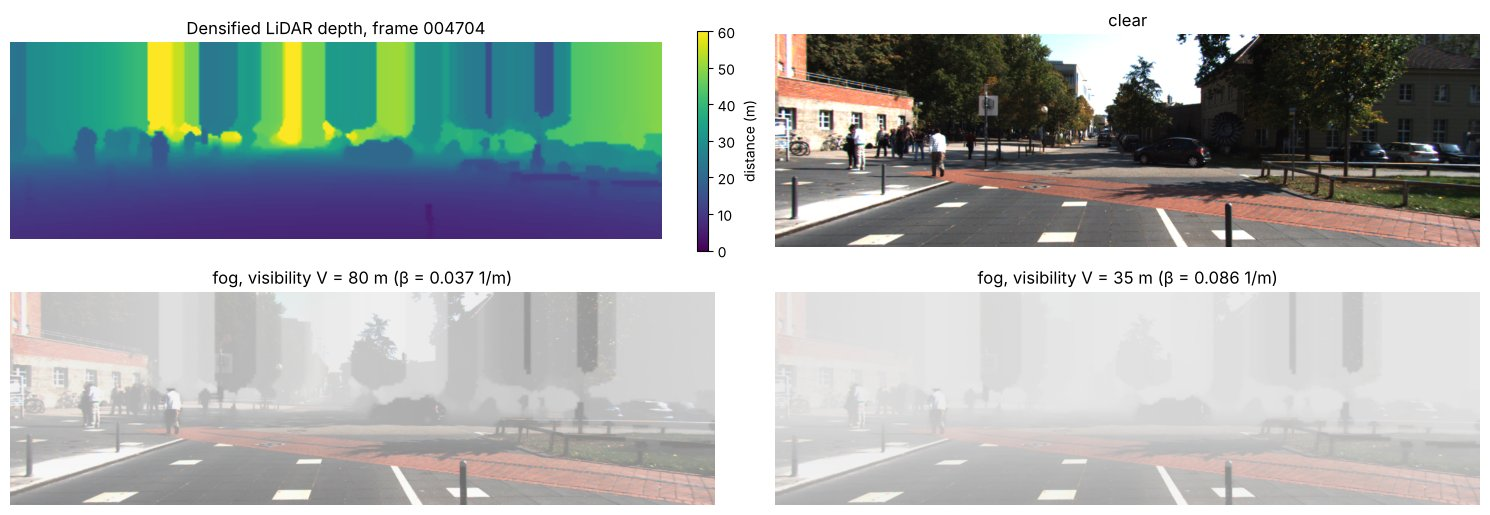

Near objects keep their contrast longest; the background disappears first — the distance dependence that a uniform contrast reduction would miss.


In [8]:
SHOW = 4704
f0 = frames[SHOW]
fig, axes = plt.subplots(2, 2, figsize=(15, 5.2))
im = axes[0, 0].imshow(depth[SHOW], cmap='viridis', vmin=0, vmax=60)
axes[0, 0].set_title(f'Densified LiDAR depth, frame {SHOW:06d}')
fig.colorbar(im, ax=axes[0, 0], fraction=0.025, label='distance (m)')
for ax, v in zip(axes.flat[1:], (np.inf, 80, 35)):
    ax.imshow(add_fog(f0.image, depth[SHOW], v))
    ax.set_title('clear' if not np.isfinite(v) else f'fog, visibility V = {v} m (β = {-np.log(0.05) / v:.3f} 1/m)')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout(); plt.show()
print("Near objects keep their contrast longest; the background disappears first — the distance dependence that a "
      "uniform contrast reduction would miss.")

### 5.2 Running the detector under each condition

Two further triggering conditions are applied to the same frames:

- **Low light with sensor noise** (L5, *night, unlit road*): the scene light is reduced by a factor $k$; the camera's
  automatic gain restores the brightness, so the image looks similar but carries photon shot noise and read noise
  (a Poisson–Gaussian model, Foi et al., 2008). Full-well capacity 4000 e⁻ and read noise 4 e⁻ are illustrative
  sensor parameters.
- **Lens dirt** (*sensor exposure*): out-of-focus, semi-opaque blobs covering 25 % of the image, placed at random
  (seeded per frame).

Each image is passed once through the detector; every labelled pedestrian and car is matched to the detections of the
corresponding COCO class (person; car or truck) by IoU. All results are kept in one table, one row per labelled object
and condition.

In [9]:
import torch
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
torch.set_num_threads(min(4, os.cpu_count()))
torch.manual_seed(0)
detector = fasterrcnn_mobilenet_v3_large_fpn(weights="DEFAULT").eval()

def detect(img):
    x = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float() / 255
    with torch.inference_mode():
        out = detector([x])[0]
    return out['boxes'].numpy(), out['scores'].numpy(), out['labels'].numpy()

def low_light(img, k, rng, full_well=4000.0, read_noise=4.0):
    """Light reduced by k, gain 1/k restores brightness; Poisson shot noise + Gaussian read noise."""
    electrons = rng.poisson(srgb_to_lin(img / 255.0) * full_well * k) + rng.normal(0, read_noise, img.shape)
    return (lin_to_srgb(electrons / (full_well * k)) * 255 + 0.5).astype(np.uint8)

def dirt_mask(shape, coverage, rng):
    H, W = shape[:2]
    yy, xx = np.mgrid[0:H, 0:W]
    mask = np.zeros((H, W))
    while (mask > 0.5).mean() < coverage:
        cy, cx, r = rng.uniform(0, H), rng.uniform(0, W), rng.uniform(25, 70)
        mask = np.maximum(mask, ((yy - cy) ** 2 + (xx - cx) ** 2 < r ** 2).astype(float))
    return 0.9 * ndimage.gaussian_filter(mask, 12)                    # opacity 0..0.9, soft edges

def lens_dirt(img, alpha, colour=(0.28, 0.22, 0.16)):
    J = img / 255.0
    blurred = ndimage.gaussian_filter(J, (6, 6, 0))
    out = (1 - alpha[..., None]) * J + alpha[..., None] * (0.5 * blurred + 0.5 * np.array(colour))
    return (np.clip(out, 0, 1) * 255 + 0.5).astype(np.uint8)

def box_iou(a, b):
    lt = np.maximum(a[:, None, :2], b[None, :, :2]); rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.prod(np.clip(rb - lt, 0, None), axis=2)
    area = lambda r: (r[:, 2] - r[:, 0]) * (r[:, 3] - r[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)

def matched_scores(gt, boxes, scores):
    """Greedy matching in descending score order; score of the matched detection per GT box (0 = missed)."""
    out = np.zeros(len(gt))
    if len(gt) and len(boxes):
        M, used = box_iou(gt, boxes), np.zeros(len(gt), bool)
        for j in np.argsort(-scores):
            cand = np.flatnonzero(~used & (M[:, j] >= IOU_THR))
            if len(cand):
                i = cand[np.argmax(M[cand, j])]; used[i] = True; out[i] = scores[j]
    return out

CONDITIONS = ([('fog', v) for v in VISIBILITIES] + [('low light', k) for k in LIGHT_FACTORS]
              + [('lens dirt', DIRT_COVERAGE)])
COCO = {'Pedestrian': [1], 'Car': [3, 8]}             # COCO ids: person; car, truck
rows, dirt_alpha = [], {}
for i, f in frames.items():
    gts = [l for l in f.labels if l['type'] in COCO]
    gt_boxes = np.array([[l['x1'], l['y1'], l['x2'], l['y2']] for l in gts]).reshape(-1, 4)
    for cond, p in CONDITIONS:
        r = np.random.default_rng(i)                                  # same noise / dirt per frame, reproducible
        if cond == 'fog':
            img = add_fog(f.image, depth[i], p)
        elif cond == 'low light':
            img = low_light(f.image, p, r)
        else:
            dirt_alpha[i] = dirt_mask(f.image.shape, p, r)
            img = lens_dirt(f.image, dirt_alpha[i])
        boxes, scores, labels = detect(img)
        for cls, ids in COCO.items():
            sel = [j for j, l in enumerate(gts) if l['type'] == cls]
            keep = np.isin(labels, ids)
            for j, s in zip(sel, matched_scores(gt_boxes[sel], boxes[keep], scores[keep])):
                l = gts[j]
                cx, cy = int((l['x1'] + l['x2']) / 2), int((l['y1'] + l['y2']) / 2)
                rows.append({'frame': i, 'condition': cond, 'param': p, 'cls': cls, 'score': s,
                             'detected': s >= SCORE_THR, 'distance_m': float(np.hypot(l['x'], l['z'])),
                             'occluded': l['occluded'], 'truncated': l['truncated'],
                             'height_px': l['y2'] - l['y1'], 'difficulty': D.kitti_difficulty(l),
                             'under_dirt': cond == 'lens dirt' and dirt_alpha[i][min(cy, f.image.shape[0] - 1), min(cx, f.image.shape[1] - 1)] > 0.5})
res = pd.DataFrame(rows)
print(f"{len(frames) * len(CONDITIONS)} detector runs; {len(res)} object-condition outcomes.")

/tmp/ipykernel_19574/4253719616.py:8: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  x = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float() / 255


270 detector runs; 2025 object-condition outcomes.


### 5.3 Recall against visibility — where is the boundary?

The evaluated population is the one the derived requirement speaks about: pedestrians within the AEB-relevant range
that KITTI rates *Easy* or *Moderate* (box height ≥ 25 px, at most partly occluded, truncation ≤ 30 %). Every recall
value carries a two-sided 95 % Clopper–Pearson interval. A condition **does not meet** the requirement only if the
whole interval lies below it; if the interval straddles it, the result is **inconclusive** and more data are needed.

n               recall                   verdict               
cls        Car Pedestrian       Car Pedestrian            Car     Pedestrian
visibility                                                                  
clear       13        144  0.923077   0.770833   inconclusive          meets
300 m       13        144  0.615385   0.666667   inconclusive   inconclusive
150 m       13        144  0.615385   0.604167   inconclusive   inconclusive
80 m        13        144  0.615385   0.618056   inconclusive   inconclusive
40 m        13        144  0.538462   0.569444   inconclusive   inconclusive
25 m        13        144  0.153846   0.520833  does not meet  does not meet

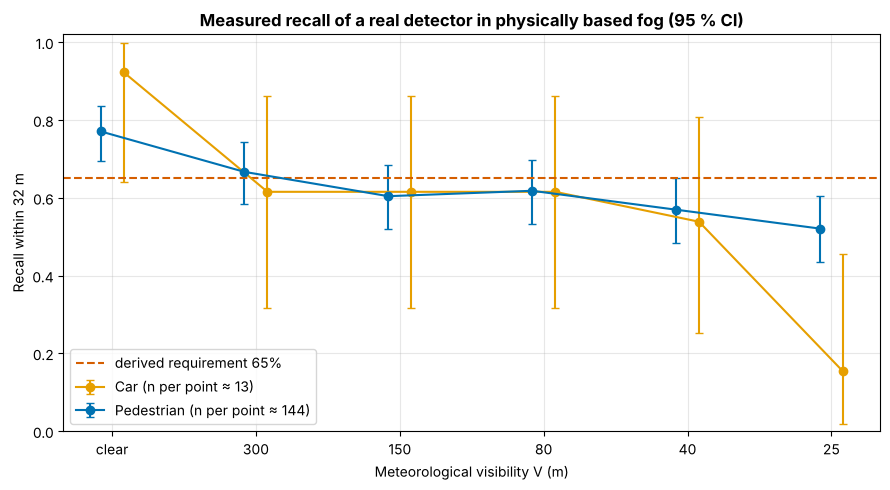

Pedestrians: requirement demonstrated down to V = inf m; clearly violated from V = 25 m; in between: [300, 150, 80, 40] (inconclusive).


In [10]:
def cp_interval(k, n, conf=0.95):
    a = 1 - conf
    lo = 0.0 if k == 0 else stats.beta.ppf(a / 2, k, n - k + 1)
    hi = 1.0 if k == n else stats.beta.ppf(1 - a / 2, k + 1, n - k)
    return lo, hi

def summarise(df):
    k, n = int(df['detected'].sum()), len(df)
    lo, hi = cp_interval(k, n)
    verdict = 'meets' if lo >= REQ_RECALL else ('does not meet' if hi < REQ_RECALL else 'inconclusive')
    return pd.Series({'n': n, 'recall': k / n, 'CI low': lo, 'CI high': hi, 'verdict': verdict})

evaluable = res['difficulty'].isin(['Easy', 'Moderate']) & (res['distance_m'] <= AEB_RANGE_M)
fog = res[evaluable & (res['condition'] == 'fog')]
fog_tab = fog.groupby(['cls', 'param']).apply(summarise, include_groups=False).reset_index()
fog_tab['visibility'] = fog_tab['param'].map(lambda v: 'clear' if not np.isfinite(v) else f'{v:.0f} m')
display(fog_tab.pivot(index='visibility', columns='cls', values=['n', 'recall', 'verdict'])
        .reindex(['clear'] + [f'{v} m' for v in VISIBILITIES[1:]]))

fig, ax = plt.subplots(figsize=(9, 5))
xpos = {v: k for k, v in enumerate(VISIBILITIES)}
for (cls, g), col, off in zip(fog_tab.groupby('cls'), (OI['orange'], OI['blue']), (0.08, -0.08)):
    x = g['param'].map(xpos) + off
    ax.errorbar(x, g['recall'], yerr=[g['recall'] - g['CI low'], g['CI high'] - g['recall']], fmt='o-',
                color=col, capsize=3, label=f'{cls} (n per point ≈ {int(g["n"].median())})')
ax.axhline(REQ_RECALL, color=OI['vermillion'], ls='--', label=f'derived requirement {REQ_RECALL:.0%}')
ax.set_xticks(range(len(VISIBILITIES)), ['clear'] + [str(v) for v in VISIBILITIES[1:]])
ax.set_xlabel('Meteorological visibility V (m)'); ax.set_ylabel(f'Recall within {AEB_RANGE_M:.0f} m')
ax.set_ylim(0, 1.02); ax.legend(loc='lower left')
ax.set_title('Measured recall of a real detector in physically based fog (95 % CI)', fontweight='bold')
plt.tight_layout(); plt.show()

ped = fog_tab[fog_tab['cls'] == 'Pedestrian'].set_index('param').loc[VISIBILITIES]
meets = [v for v in VISIBILITIES if ped.loc[v, 'verdict'] == 'meets']
fails = [v for v in VISIBILITIES if ped.loc[v, 'verdict'] == 'does not meet']
V_LAST_MEET = min(meets) if meets else None
V_FIRST_FAIL = max(fails) if fails else None
fmt_v = lambda v: 'clear air' if v is None or not np.isfinite(v) else f'V = {v:.0f} m'
print(f"Pedestrians: requirement demonstrated down to {fmt_v(V_LAST_MEET)}; clearly violated from {fmt_v(V_FIRST_FAIL)}; "
      f"inconclusive at {[fmt_v(v) for v in VISIBILITIES if ped.loc[v, 'verdict'] == 'inconclusive']} "
      f"with {int(ped['n'].iloc[0])} pedestrians per condition.")

Reading the result as a SOTIF engineer:

- The **boundary is a bracket, not a number**: between the lowest visibility where the requirement is demonstrated
  and the highest where it is clearly violated. Narrowing it needs more pedestrians, not more decimal places.
- The degradation is a **performance insufficiency of the detector**, activated by the triggering condition *dense
  fog*. Whether it causes hazardous behaviour depends on the rest of the function (radar, confirmation, braking
  strategy) — a closed-loop question for clause 10.
- The fog is **synthetic on real images**. It follows the physics of attenuation and airlight but omits scattering
  blur, inhomogeneous fog, and the reaction of the camera's exposure control. Its credibility for the safety argument
  must be shown, e.g. by comparing with a real-fog dataset such as Seeing Through Fog (Bijelic et al., 2020).

### 5.4 Recall against distance: from a boundary to an ODD restriction

Fog hurts distant pedestrians first. Fitting a logistic curve $P(\text{detected}\mid d)$ per visibility gives the
**range up to which the requirement holds**, $R_{\text{req}}(V)$. If the function may only rely on detections within
that range, the highest speed whose stopping distance fits inside it follows from
$v\,\tau + v^2/(2a) = R_{\text{req}}$ — a *speed restriction as a function of visibility*, the shape of many real ODD
restrictions.

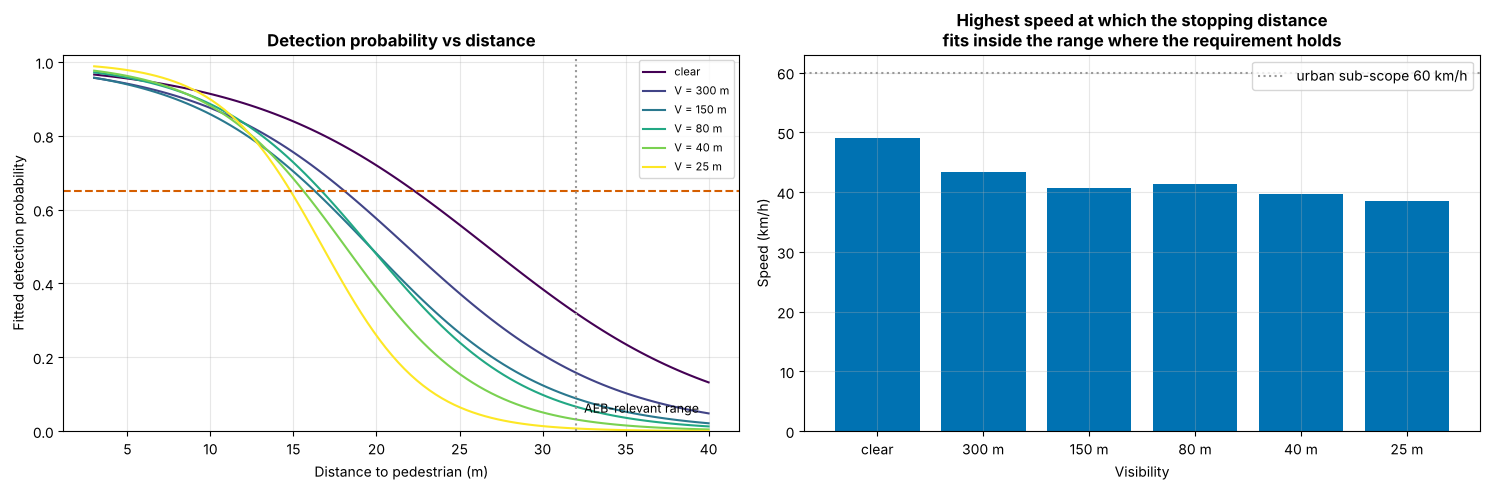

,visibility,n pedestrians,range with recall ≥ req (m),max speed (km/h)
0,clear,154,22.3,49.1
1,300 m,154,18.1,43.3
2,150 m,154,16.3,40.7
3,80 m,154,16.7,41.3
4,40 m,154,15.6,39.6
5,25 m,154,14.8,38.4


Text summary: even in clear air the requirement holds only up to about 22 m, which supports 49 km/h — the range-aggregated requirement of 5.3 hides this, so it should be stated per distance band. In the densest fog tested the range shrinks to 15 m (38 km/h).
Ranges are capped at 40 m, the largest distance in the evaluated sample; a logistic fit on 154 pedestrians per visibility is an estimate, not a bound.


In [11]:
def fit_logistic(d, y):
    """Maximum-likelihood logistic regression P(y=1 | d) = 1 / (1 + exp(-(a + b d)))."""
    nll = lambda p: np.sum(np.logaddexp(0, -(p[0] + p[1] * d)) * y + np.logaddexp(0, p[0] + p[1] * d) * (1 - y))
    return optimize.minimize(nll, x0=[2.0, -0.05], method='Nelder-Mead').x

def range_meeting(a, b, req=REQ_RECALL, d_max=40.0):
    """Largest distance (≤ d_max) at which the fitted detection probability is still ≥ req."""
    d_star = (np.log(req / (1 - req)) - a) / b if b < 0 else np.inf
    return float(np.clip(d_star, 0.0, d_max))

def v_max_kmh(range_m, tau=T_REACT_S, a=DECEL):
    """Speed whose stopping distance equals range_m: v tau + v^2 / (2a) = R."""
    return 3.6 * a * (-tau + np.sqrt(tau ** 2 + 2 * range_m / a))

ped_all = res[(res['cls'] == 'Pedestrian') & res['difficulty'].isin(['Easy', 'Moderate'])
              & (res['distance_m'] <= 40) & (res['condition'] == 'fog')]
d_grid = np.linspace(3, 40, 100)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
cmap = plt.get_cmap('viridis')
restr = []
for k, v in enumerate(VISIBILITIES):
    g = ped_all[ped_all['param'] == v]
    a, b = fit_logistic(g['distance_m'].to_numpy(), g['detected'].to_numpy().astype(float))
    R = range_meeting(a, b)
    restr.append({'visibility': 'clear' if not np.isfinite(v) else f'{v} m', 'V_m': v, 'n pedestrians': len(g),
                  'range with recall ≥ req (m)': R, 'max speed (km/h)': v_max_kmh(R)})
    ax1.plot(d_grid, 1 / (1 + np.exp(-(a + b * d_grid))), color=cmap(k / (len(VISIBILITIES) - 1)),
             label='clear' if not np.isfinite(v) else f'V = {v} m')
ax1.axhline(REQ_RECALL, color=OI['vermillion'], ls='--'); ax1.axvline(AEB_RANGE_M, color=OI['grey'], ls=':')
ax1.text(AEB_RANGE_M + 0.5, 0.05, 'AEB-relevant range', fontsize=9)
ax1.set_xlabel('Distance to pedestrian (m)'); ax1.set_ylabel('Fitted detection probability')
ax1.set_ylim(0, 1.02); ax1.legend(fontsize=8); ax1.set_title('Detection probability vs distance', fontweight='bold')
restr = pd.DataFrame(restr)
xs = np.arange(len(restr))
ax2.bar(xs, restr['max speed (km/h)'], color=OI['blue'])
ax2.axhline(V_URBAN_KMH, color=OI['grey'], ls=':', label=f'urban sub-scope {V_URBAN_KMH} km/h')
ax2.set_xticks(xs, restr['visibility']); ax2.set_xlabel('Visibility'); ax2.set_ylabel('Speed (km/h)')
ax2.set_title('Highest speed at which the stopping distance\nfits inside the range where the requirement holds', fontweight='bold')
ax2.legend(); plt.tight_layout(); plt.show()
display(restr.drop(columns='V_m').round(1))
r_clear = restr.loc[0, 'range with recall ≥ req (m)']
print(f"Text summary: even in clear air the requirement holds only up to about {r_clear:.0f} m, which supports "
      f"{v_max_kmh(r_clear):.0f} km/h — the range-aggregated requirement of 5.3 hides this, so it should be stated per "
      f"distance band. In the densest fog tested the range shrinks to {restr['range with recall ≥ req (m)'].iloc[-1]:.0f} m "
      f"({restr['max speed (km/h)'].iloc[-1]:.0f} km/h).")
print("Ranges are capped at 40 m, the largest distance in the evaluated sample; a logistic fit on "
      f"{int(restr['n pedestrians'].median())} pedestrians per visibility is an estimate, not a bound.")

### 5.5 Low light, lens dirt and occlusion

The same procedure for the other conditions. For lens dirt the comparison that matters is **inside versus outside**
the dirty area: an average over the whole image hides that a pedestrian behind a dirt blob is simply invisible. For
partial occlusion the KITTI annotation itself is the parameter (0 fully visible, 1 partly occluded, 2 largely
occluded), measured on the clear images.

,n,recall,CI low,CI high,verdict
clear (reference),144,0.77,0.69,0.84,meets
"low light, k = 1/64",144,0.44,0.36,0.52,does not meet
"low light, k = 1/256",144,0.27,0.20,0.35,does not meet
"lens dirt, pedestrian outside dirt",97,0.69,0.59,0.78,inconclusive
"lens dirt, pedestrian behind dirt",47,0.51,0.36,0.66,inconclusive
"clear, KITTI occlusion 0 (fully visible)",101,0.84,0.76,0.91,meets
"clear, KITTI occlusion 1 (partly occluded)",46,0.59,0.43,0.73,inconclusive
"clear, KITTI occlusion 2 (largely occluded)",20,0.40,0.19,0.64,does not meet


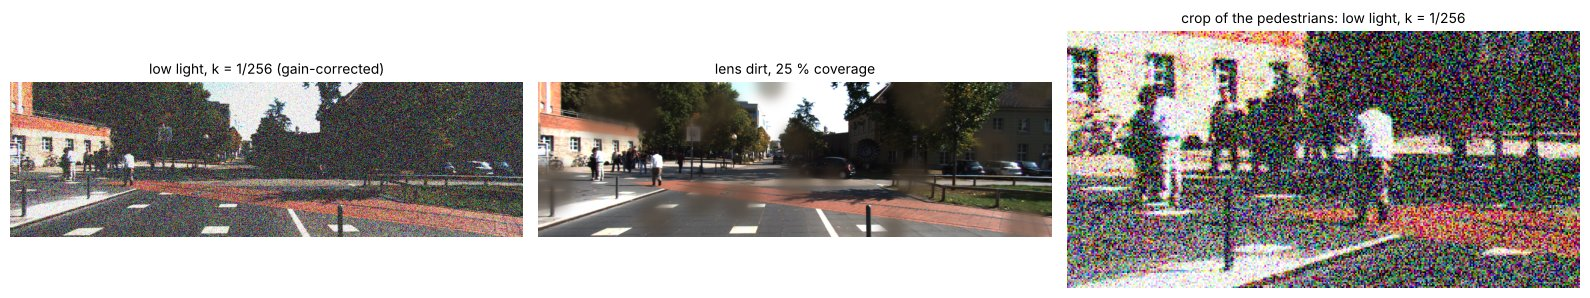

In [12]:
near_ped = res[(res['cls'] == 'Pedestrian') & (res['distance_m'] <= AEB_RANGE_M)]
base = near_ped[near_ped['difficulty'].isin(['Easy', 'Moderate'])]
groups = {
    'clear (reference)': base[(base['condition'] == 'fog') & ~np.isfinite(base['param'])],
    **{f'low light, k = 1/{1 / k:.0f}': base[(base['condition'] == 'low light') & np.isclose(base['param'], k)]
       for k in LIGHT_FACTORS},
    'lens dirt, pedestrian outside dirt': base[(base['condition'] == 'lens dirt') & ~base['under_dirt'].astype(bool)],
    'lens dirt, pedestrian behind dirt': base[(base['condition'] == 'lens dirt') & base['under_dirt'].astype(bool)],
}
clear_all = near_ped[(near_ped['condition'] == 'fog') & ~np.isfinite(near_ped['param'])
                     & (near_ped['height_px'] >= 25) & (near_ped['truncated'] <= 0.5)]
for occ, name in [(0, 'fully visible'), (1, 'partly occluded'), (2, 'largely occluded')]:
    groups[f'clear, KITTI occlusion {occ} ({name})'] = clear_all[clear_all['occluded'] == occ]
other = pd.DataFrame({g: summarise(df) for g, df in groups.items() if len(df)}).T
display(other.style.format({'n': '{:.0f}', 'recall': '{:.2f}', 'CI low': '{:.2f}', 'CI high': '{:.2f}'}))

fig, axes = plt.subplots(1, 3, figsize=(16, 2.9))
ex = frames[SHOW].image
for ax, (title, img) in zip(axes, [('low light, k = 1/256 (gain-corrected)', low_light(ex, 1 / 256, np.random.default_rng(SHOW))),
                                   ('lens dirt, 25 % coverage', lens_dirt(ex, dirt_alpha[SHOW])),
                                   ('crop of the pedestrians: low light, k = 1/256', low_light(ex, 1 / 256, np.random.default_rng(SHOW))[120:290, 80:420])]):
    ax.imshow(img); ax.set_title(title, fontsize=10); ax.axis('off')
plt.tight_layout(); plt.show()

### 5.6 And the LiDAR? Fog on real scans

LiDAR brings its own light, so darkness does not matter — but fog attenuates the beam on the way out *and* back
($e^{-2\beta R}$) and scatters light back from the droplets. A simple **link-budget model** on the real scans keeps a
return only if its received power stays above the sensor's detection threshold:

$$\frac{\rho\,e^{-2\beta R}}{R^2} \ge P_{\min}, \qquad P_{\min} = \frac{0.10}{(50\ \text{m})^2},$$

where $P_{\min}$ follows from the HDL-64E specification (pavement of about 10 % reflectivity is detected up to 50 m;
the same threshold gives about 120 m for 80 % targets, as specified). The stored KITTI intensity serves as
reflectivity $\rho$, raised where necessary so that every recorded return passes in clear air. The extinction
coefficient at 905 nm is taken equal to the visible one, a fair approximation for fog droplets, which are much larger
than both wavelengths. This model **omits backscatter clutter and the receiver's behaviour**; Hahner et al. (2021)
simulate both on real point clouds. Below: LiDAR points on each evaluable pedestrian within the AEB range.

,median_points,share_with_min_points
clear,112.0,1.00
300.0 m,111.0,1.00
150.0 m,111.0,1.00
80.0 m,111.0,0.97
40.0 m,103.5,0.73
25.0 m,30.0,0.51


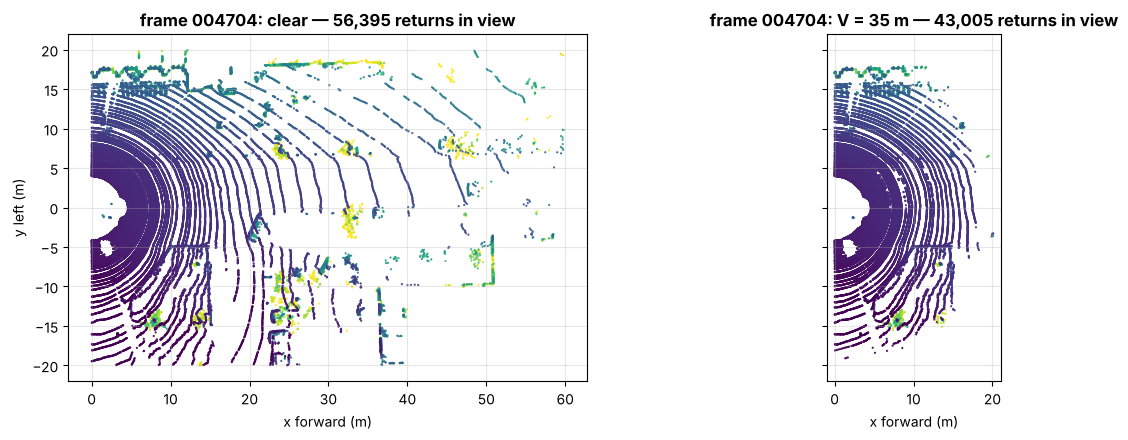

Text summary: median LiDAR points per pedestrian (≤ 32 m) fall from 112 in clear air to 30 at V = 25 m.


In [13]:
P_MIN = 0.10 / 50.0 ** 2

def lidar_in_fog(points, visibility_m):
    """Keep returns whose two-way attenuated power stays above P_MIN (no backscatter modelled)."""
    if not np.isfinite(visibility_m):
        return points
    R = np.linalg.norm(points[:, :3], axis=1).clip(0.5)
    rho = np.maximum(points[:, 3], P_MIN * R ** 2)                 # every recorded return passes in clear air
    beta = -np.log(0.05) / visibility_m
    return points[rho * np.exp(-2 * beta * R) / R ** 2 >= P_MIN]

def points_in_box(frame, pts, label):
    rect = frame.velo_to_rect(pts)
    d = rect - np.array([label['x'], label['y'], label['z']])
    c, s = np.cos(label['rotation_y']), np.sin(label['rotation_y'])
    x_loc, z_loc = c * d[:, 0] - s * d[:, 2], s * d[:, 0] + c * d[:, 2]
    return int(np.sum((np.abs(x_loc) <= label['l'] / 2) & (np.abs(z_loc) <= label['w'] / 2)
                      & (d[:, 1] <= 0) & (d[:, 1] >= -label['h'])))

lid = []
for i, f in frames.items():
    peds = [l for l in f.labels if l['type'] == 'Pedestrian' and D.kitti_difficulty(l) in ('Easy', 'Moderate')
            and np.hypot(l['x'], l['z']) <= AEB_RANGE_M]
    for v in VISIBILITIES:
        pts = lidar_in_fog(f.points, v)
        lid += [{'V': v, 'points': points_in_box(f, pts, l), 'distance_m': np.hypot(l['x'], l['z'])} for l in peds]
lid = pd.DataFrame(lid)
MIN_PTS = 10      # illustrative: points a LiDAR detector needs to find and classify a pedestrian
lid_tab = lid.groupby('V').agg(median_points=('points', 'median'),
                               share_with_min_points=('points', lambda p: np.mean(p >= MIN_PTS))).loc[VISIBILITIES]
lid_tab.index = ['clear' if not np.isfinite(v) else f'{v} m' for v in lid_tab.index]
display(lid_tab.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, v in zip(axes, (np.inf, 35)):
    p = lidar_in_fog(frames[SHOW].points, v)
    p = p[(p[:, 0] > 0) & (p[:, 0] < 60) & (np.abs(p[:, 1]) < 20)]
    ax.scatter(p[:, 0], p[:, 1], s=0.3, c=p[:, 2], cmap='viridis', vmin=-2, vmax=1)
    ax.set_title(f"frame {SHOW:06d}: {'clear' if not np.isfinite(v) else f'V = {v} m'} — {len(p):,} returns in view",
                 fontweight='bold')
    ax.set_xlabel('x forward (m)'); ax.set_aspect('equal')
axes[0].set_ylabel('y left (m)'); plt.tight_layout(); plt.show()
print(f"Text summary: median LiDAR points per pedestrian (≤ {AEB_RANGE_M:.0f} m) fall from "
      f"{lid_tab['median_points'].iloc[0]:.0f} in clear air to {lid_tab['median_points'].iloc[-1]:.0f} at V = {VISIBILITIES[-1]} m.")

### 5.7 The triggering-condition table

The measurements become an entry in the SOTIF analysis. The table below follows the structure used in industry
triggering-condition analyses: the condition (with its catalogue ID and 6-layer group), the **parameter range** in
which it is a problem, the affected element, the **measured** effect, the **measure** (ISO 21448 clause 8:
functional modification or ODD restriction) and the verification that closes it. Numbers are filled in from the
results above; the measures are proposals that the function team would evaluate.

In [14]:
tc_id = dict(zip(tc_df['Triggering condition'], tc_df['TC-ID']))
o = other['recall']
ll_worst = f'low light, k = 1/{1 / LIGHT_FACTORS[-1]:.0f}'
fail_txt = (f"V ≤ {V_FIRST_FAIL} m (recall {ped.loc[V_FIRST_FAIL, 'recall']:.0%}, CI upper {ped.loc[V_FIRST_FAIL, 'CI high']:.0%})"
            if V_FIRST_FAIL is not None else 'not reached in tested range')
boundary = (f"between {fmt_v(V_FIRST_FAIL)} (fails) and {fmt_v(V_LAST_MEET)} (meets)"
            if V_FIRST_FAIL is not None and V_LAST_MEET is not None else 'not bracketed by the tested visibilities')
v_ok = restr.loc[restr['V_m'] == (V_FIRST_FAIL if V_FIRST_FAIL is not None else VISIBILITIES[-1]), 'max speed (km/h)'].iloc[0]
tc_table = pd.DataFrame([
    {'TC': tc_id['Dense fog'], 'Condition (layer)': 'Dense fog (L5)',
     'Parameter range': f'visibility V; boundary {boundary}',
     'Affected element': 'Camera pedestrian detector',
     'Measured effect': f'recall ≤ {AEB_RANGE_M:.0f} m: clear {ped.loc[np.inf, "recall"]:.0%} → {fail_txt}',
     'Measure': f'ODD restriction: below the boundary, limit speed (≈ {v_ok:.0f} km/h from 5.4) or rely on radar; '
                'visibility estimation as ODD monitor',
     'Verification': 'Real-fog data set or fog chamber; closed-loop AEB test at the boundary'},
    {'TC': tc_id['Night, unlit road'], 'Condition (layer)': 'Night, unlit road (L5)',
     'Parameter range': f'scene light k ≤ 1/{1 / LIGHT_FACTORS[0]:.0f} of daylight exposure',
     'Affected element': 'Camera + detector (noise after gain)',
     'Measured effect': f'recall {o["clear (reference)"]:.0%} → {o[ll_worst]:.0%} at k = 1/{1 / LIGHT_FACTORS[-1]:.0f}',
     'Measure': 'Functional modification: low-light training data, radar confirmation; headlight-range ODD limit',
     'Verification': 'Night drives with labelled pedestrians; proving ground with illuminance measured'},
    {'TC': tc_id['Dirt or mud on lens'], 'Condition (layer)': 'Dirt on lens (sensor exposure)',
     'Parameter range': f'{DIRT_COVERAGE:.0%} of image covered',
     'Affected element': 'Camera optics + detector',
     'Measured effect': f'recall outside dirt {o["lens dirt, pedestrian outside dirt"]:.0%}, behind dirt '
                        f'{o["lens dirt, pedestrian behind dirt"]:.0%}',
     'Measure': 'Blockage detection + cleaning; degrade function and inform driver when blocked',
     'Verification': 'Blockage detector rate on dirt/clean set; field data on cleaning effectiveness'},
    {'TC': tc_id['Row of parked vehicles'], 'Condition (layer)': 'Pedestrian occluded by parked vehicles (L2/L4)',
     'Parameter range': 'KITTI occlusion level 2 (largely occluded)',
     'Affected element': 'Camera pedestrian detector',
     'Measured effect': f'recall {o["clear, KITTI occlusion 0 (fully visible)"]:.0%} (visible) → '
                        f'{o["clear, KITTI occlusion 2 (largely occluded)"]:.0%} (largely occluded)',
     'Measure': 'Specification: reduced speed next to parked cars; tracking of partially visible objects',
     'Verification': 'Occlusion scenarios (functional → logical) in simulation and proving ground'},
    {'TC': tc_id['Dense fog'], 'Condition (layer)': 'Dense fog (L5), LiDAR path',
     'Parameter range': f'V ≤ {VISIBILITIES[-1]} m',
     'Affected element': 'LiDAR (if used for confirmation)',
     'Measured effect': f'points per pedestrian {lid_tab["median_points"].iloc[0]:.0f} → '
                        f'{lid_tab["median_points"].iloc[-1]:.0f} (attenuation model, no backscatter)',
     'Measure': 'Do not count LiDAR as independent confirmation in dense fog',
     'Verification': 'Fog-chamber or real-fog LiDAR data (backscatter!)'},
])
with pd.option_context('display.max_colwidth', 120):
    display(tc_table)

,TC,Condition (layer),Parameter range,Affected element,Measured effect,Measure,Verification
0,TC-18,Dense fog (L5),visibility V; boundary between 25 and inf m,Camera pedestrian detector,"recall ≤ 32 m: clear 77% → V ≤ 25 m (recall 52%, CI upper 60%)","ODD restriction: below the boundary, limit speed (≈ 38 km/h from 5.4) or rely on radar; visibility estimation as ODD...",Real-fog data set or fog chamber; closed-loop AEB test at the boundary
1,TC-21,"Night, unlit road (L5)",scene light k ≤ 1/64 of daylight exposure,Camera + detector (noise after gain),recall 77% → 27% at k = 1/256,"Functional modification: low-light training data, radar confirmation; headlight-range ODD limit",Night drives with labelled pedestrians; proving ground with illuminance measured
2,TC-26,Dirt on lens (sensor exposure),25% of image covered,Camera optics + detector,"recall outside dirt 69%, behind dirt 51%",Blockage detection + cleaning; degrade function and inform driver when blocked,Blockage detector rate on dirt/clean set; field data on cleaning effectiveness
3,TC-05,Pedestrian occluded by parked vehicles (L2/L4),KITTI occlusion level 2 (largely occluded),Camera pedestrian detector,recall 84% (visible) → 40% (largely occluded),Specification: reduced speed next to parked cars; tracking of partially visible objects,Occlusion scenarios (functional → logical) in simulation and proving ground
4,TC-18,"Dense fog (L5), LiDAR path",V ≤ 25 m,LiDAR (if used for confirmation),"points per pedestrian 112 → 30 (attenuation model, no backscatter)",Do not count LiDAR as independent confirmation in dense fog,Fog-chamber or real-fog LiDAR data (backscatter!)


Three things make this table useful to an assessor, and all three come from the measurement rather than from
judgement: the **parameter range** is stated as a boundary with its uncertainty, the **effect** is quantified on
the component that will be released, and every row names how it will be **verified**. What it does *not* show is
whether the function is hazardous at the boundary — that needs the closed-loop evaluation (clause 10) — or which
conditions are missing from the catalogue (clause 11, Area 3).

## 6. ISO 34502:2022 — scenario-based safety evaluation framework

**ISO 34502:2022** *Road vehicles — Test scenarios for automated driving systems — Scenario based safety evaluation
framework* gives guidance for building and using a scenario space during ADS development. Its scope is ADS on
**limited-access highways**; misuse, HMI and cybersecurity are excluded. The framework is aligned with ISO 21448 and
adds a scenario-based process for identifying risk factors. In outline:

1. **Identify risk factors** from the ODD and the system (perception, planning, vehicle motion).
2. **Structure critical scenarios** systematically, rooted in physical principles of how disturbances arise; the
   framework, which builds on the Japanese JAMA/SAKURA approach, distinguishes disturbances related to traffic,
   to perception and to vehicle motion *(terms paraphrased; check the standard's own wording)*.
3. **Parameterise** them as logical scenarios and derive concrete test scenarios.
4. **Evaluate** by simulation, proving ground and public-road tests against defined criteria; an informative annex
   discusses risk evaluation based on a positive risk balance.

**ISO 34503:2023** (ODD taxonomy, above) and **ISO 34504** (scenario categorisation) complete the ISO 345xx family.

## 7. Hands-on: scenario space and n-wise coverage

We build the logical scenario *"pedestrian crossing in front of an urban AEB vehicle"* with seven discretised
parameters. A full-factorial design quickly becomes large; **combinatorial (n-wise) testing** asks instead that every
combination of values of any *n* parameters appears in at least one test. Many failures are caused by interactions
of few parameters, so pairwise (n = 2) or 3-wise test sets find much with few tests (see the NIST combinatorial-testing resources in the references).

The coverage function below reproduces `avsafety.coverage.nwise_coverage` (see repo `avsafety/`) and adds an optional
`valid` filter, so that physically impossible combinations (rain on a dry road) are not counted as gaps.

In [15]:
# Logical scenario: discretised parameter domains
domains = {
    'ego_speed_kmh': [30, 40, 50],
    'illumination': ['day', 'dusk', 'night_lit'],
    'precipitation': ['none', 'light_rain', 'heavy_rain'],
    'road_surface': ['dry', 'wet'],
    'pedestrian': ['adult', 'child', 'wheelchair'],
    'occlusion': ['none', 'parked_car'],
    'ped_motion': ['walk', 'run'],
}

def is_valid(sc):
    """Physical constraint: precipitation implies a wet road."""
    return not (sc['precipitation'] != 'none' and sc['road_surface'] == 'dry')

def full_factorial(domains):
    keys = sorted(domains)
    return [dict(zip(keys, vals)) for vals in product(*(domains[k] for k in keys))]

def nwise_coverage(domains, scenarios, n=2, valid=None):
    """Fraction of n-way value combinations exercised by `scenarios`.
    With valid=None this equals avsafety.coverage.nwise_coverage; with a `valid` predicate only combinations
    that occur in at least one valid full scenario are required."""
    params = sorted(domains)
    if valid is None:
        required = {tuple(zip(c, v)) for c in combinations(params, n) for v in product(*(domains[p] for p in c))}
    else:
        required = {tuple((p, sc[p]) for p in c) for sc in full_factorial(domains) if valid(sc)
                    for c in combinations(params, n)}
    seen = {tuple((p, sc[p]) for p in c) for sc in scenarios for c in combinations(params, n)}
    covered = required & seen
    return {'coverage': len(covered) / len(required), 'covered': len(covered), 'total': len(required),
            'missing': sorted(required - seen)}

universe = [sc for sc in full_factorial(domains) if is_valid(sc)]
print(f"Full factorial: {len(full_factorial(domains))} concrete scenarios, of which {len(universe)} are physically valid")
for n in (1, 2, 3):
    print(f"  required {n}-wise value combinations (valid only): {nwise_coverage(domains, [], n, is_valid)['total']}")

Full factorial: 648 concrete scenarios, of which 432 are physically valid
  required 1-wise value combinations (valid only): 18
  required 2-wise value combinations (valid only): 136
  required 3-wise value combinations (valid only): 558


### 7.1 A pairwise test set

A simple greedy algorithm (in the spirit of AETG) repeatedly picks the valid concrete scenario that covers the most
not-yet-covered pairs. Compare its size with random sampling.

Greedy pairwise suite: 15 tests → 2-wise coverage 100%, 3-wise coverage 65% (out of 432 valid scenarios)


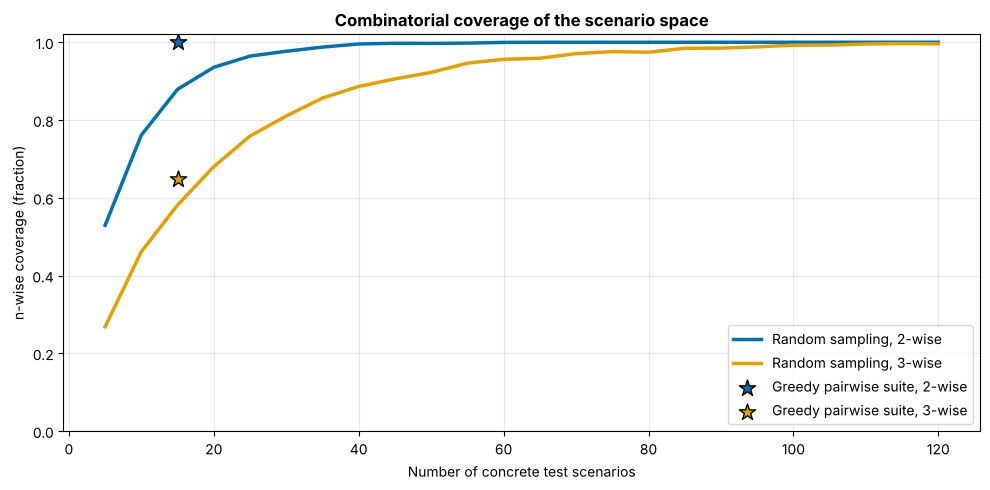

Text summary: 15 greedy tests give full pairwise coverage; random sampling needs about 60 tests on average.


In [16]:
def pairs_of(sc, params):
    return {tuple((p, sc[p]) for p in c) for c in combinations(params, 2)}

def greedy_pairwise(universe, domains):
    params = sorted(domains)
    candidate_pairs = [pairs_of(sc, params) for sc in universe]
    uncovered = set().union(*candidate_pairs)
    suite = []
    while uncovered:
        gains = [len(cp & uncovered) for cp in candidate_pairs]
        best = int(np.argmax(gains))
        suite.append(universe[best])
        uncovered -= candidate_pairs[best]
    return suite

pairwise_suite = greedy_pairwise(universe, domains)
cov2 = nwise_coverage(domains, pairwise_suite, 2, is_valid)
cov3 = nwise_coverage(domains, pairwise_suite, 3, is_valid)
print(f"Greedy pairwise suite: {len(pairwise_suite)} tests → 2-wise coverage {cov2['coverage']:.0%}, "
      f"3-wise coverage {cov3['coverage']:.0%} (out of {len(universe)} valid scenarios)")

# Random sampling for comparison (mean over 20 repetitions)
sizes = np.arange(5, 121, 5)
rand_cov = {2: [], 3: []}
for n_tests in sizes:
    for n in (2, 3):
        vals = []
        for _ in range(20):
            idx = rng.choice(len(universe), size=n_tests, replace=False)
            vals.append(nwise_coverage(domains, [universe[i] for i in idx], n, is_valid)['coverage'])
        rand_cov[n].append(np.mean(vals))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sizes, rand_cov[2], color=OI['blue'], lw=2.5, label='Random sampling, 2-wise')
ax.plot(sizes, rand_cov[3], color=OI['orange'], lw=2.5, label='Random sampling, 3-wise')
ax.scatter([len(pairwise_suite)], [cov2['coverage']], s=150, color=OI['blue'], marker='*', zorder=5,
           edgecolor='black', label='Greedy pairwise suite, 2-wise')
ax.scatter([len(pairwise_suite)], [cov3['coverage']], s=150, color=OI['orange'], marker='*', zorder=5,
           edgecolor='black', label='Greedy pairwise suite, 3-wise')
ax.set_xlabel('Number of concrete test scenarios'); ax.set_ylabel('n-wise coverage (fraction)')
ax.set_ylim(0, 1.02); ax.set_title('Combinatorial coverage of the scenario space', fontweight='bold')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

n_rand_full = sizes[np.argmax(np.array(rand_cov[2]) >= 0.999)] if max(rand_cov[2]) >= 0.999 else None
print(f"Text summary: {len(pairwise_suite)} greedy tests give full pairwise coverage; random sampling needs "
      f"{'about ' + str(n_rand_full) if n_rand_full else 'more than ' + str(sizes[-1])} tests on average.")

### 7.2 Evaluating the concrete scenarios

To see what the test set finds we need a model of the system's behaviour. Below is a deliberately simple,
**transparent** model of an AEB function: the pedestrian is detected at a range that depends on illumination,
precipitation and pedestrian type; an occluded pedestrian becomes visible only when stepping out; the vehicle then
needs reaction distance plus braking distance (as in `avsafety.sotif.stopping_distance`). The scenario is **hazardous**
if the vehicle cannot stop before the conflict point.

> **Illustrative data:** the detection ranges and factors below are synthetic, chosen for teaching; they are not
> measurements of any real system.

In [17]:
# Synthetic system model (all factors are teaching values)
BASE_RANGE_M = 45.0
F_ILLUM = {'day': 1.0, 'dusk': 0.8, 'night_lit': 0.6}
F_PRECIP = {'none': 1.0, 'light_rain': 0.9, 'heavy_rain': 0.7}
F_PED = {'adult': 1.0, 'child': 0.85, 'wheelchair': 0.8}
DECEL = {'dry': 8.0, 'wet': 5.5}           # achievable deceleration, m/s^2
REACTION_S = 0.5                           # confirmation + brake build-up, s
LATERAL_M = 2.5                            # distance from kerb (behind parked car) to the vehicle path, m
PED_SPEED = {'walk': 1.4, 'run': 3.0}      # m/s

def stopping_distance(v, reaction_s, decel):
    """Reaction distance plus braking distance (m) — same as avsafety.sotif.stopping_distance."""
    return v * reaction_s + v ** 2 / (2 * decel)

def evaluate(sc):
    v = sc['ego_speed_kmh'] / 3.6
    detect = BASE_RANGE_M * F_ILLUM[sc['illumination']] * F_PRECIP[sc['precipitation']] * F_PED[sc['pedestrian']]
    if sc['occlusion'] == 'parked_car':
        visible_from = v * LATERAL_M / PED_SPEED[sc['ped_motion']]   # ego distance when the pedestrian steps out
        available = min(detect, visible_from)
    else:
        available = detect
    needed = stopping_distance(v, REACTION_S, DECEL[sc['road_surface']])
    return {'available_m': available, 'needed_m': needed, 'hazardous': needed > available}

uni_df = pd.DataFrame(universe)
uni_df = pd.concat([uni_df, pd.DataFrame([evaluate(sc) for sc in universe])], axis=1)
suite_df = pd.DataFrame(pairwise_suite)
suite_df = pd.concat([suite_df, pd.DataFrame([evaluate(sc) for sc in pairwise_suite])], axis=1)

# Which failures exist in the whole (valid) space? Group by the parameter values that drive them.
params = sorted(domains)
def failure_inducing_pairs(df):
    out = []
    for a, b in combinations(params, 2):
        rate = df.groupby([a, b])['hazardous'].mean()
        for (va, vb), r in rate.items():
            if r == 1.0:
                out.append(((a, va), (b, vb)))
    return out

fip = failure_inducing_pairs(uni_df)
print(f"Valid scenario space: {len(uni_df)} scenarios, {uni_df['hazardous'].sum()} hazardous "
      f"({uni_df['hazardous'].mean():.0%}).")
print(f"Value pairs that are hazardous in *every* scenario containing them: {fip}")
print(f"Pairwise suite: {len(suite_df)} tests, {suite_df['hazardous'].sum()} hazardous.")

# Hazardous scenarios that are NOT explained by a failure-inducing pair → higher-order interactions
def explained(row):
    return any(all(row[p] == v for p, v in pair) for pair in fip)
higher = uni_df[uni_df['hazardous'] & ~uni_df.apply(explained, axis=1)]
found_higher = suite_df[suite_df['hazardous'] & ~suite_df.apply(explained, axis=1)]
print(f"Hazardous scenarios caused by interactions of 3 or more parameters: {len(higher)} in the space, "
      f"{len(found_higher)} of them hit by the pairwise suite.")
display(higher.drop(columns=['available_m', 'needed_m']).head(8))

Valid scenario space: 432 scenarios, 144 hazardous (33%).
Value pairs that are hazardous in *every* scenario containing them: [(('occlusion', 'parked_car'), ('ped_motion', 'run'))]
Pairwise suite: 15 tests, 5 hazardous.
Hazardous scenarios caused by interactions of 3 or more parameters: 36 in the space, 2 of them hit by the pairwise suite.


,ego_speed_kmh,illumination,occlusion,ped_motion,pedestrian,precipitation,road_surface,hazardous
247,40,night_lit,none,walk,child,heavy_rain,wet,True
251,40,night_lit,none,walk,wheelchair,heavy_rain,wet,True
259,40,night_lit,none,run,child,heavy_rain,wet,True
263,40,night_lit,none,run,wheelchair,heavy_rain,wet,True
271,40,night_lit,parked_car,walk,child,heavy_rain,wet,True
275,40,night_lit,parked_car,walk,wheelchair,heavy_rain,wet,True
343,50,dusk,none,walk,child,heavy_rain,wet,True
347,50,dusk,none,walk,wheelchair,heavy_rain,wet,True


What the result shows:

- A **pair** of values (occluded pedestrian *and* running) makes the scenario hazardous whatever else happens — a
  pairwise test set is guaranteed to contain it. Note that this one is a **physical limit** (no system can stop in
  time), so the fitting measure is a *specification* change — e.g. lower speed next to parked cars — not a better
  detector.
- Other hazardous scenarios need **three or more** conditions together (darkness × rain × small road user × speed
  × wet road). A pairwise set finds them only by luck; 3-wise or targeted search is needed. That is why ISO 21448
  asks for the analysis of **combinations of triggering conditions**.

### 7.3 From test results to areas

Only scenarios that have been **evaluated** can be placed in Area 1 or Area 2. Scenarios inside the defined space that
have not been run are *known but not yet evaluated*. Scenarios **outside** the parameterisation — a pedestrian with
an umbrella, a mobility scooter — are candidates for Area 3 or Area 4 and cannot be classified by this code at all.

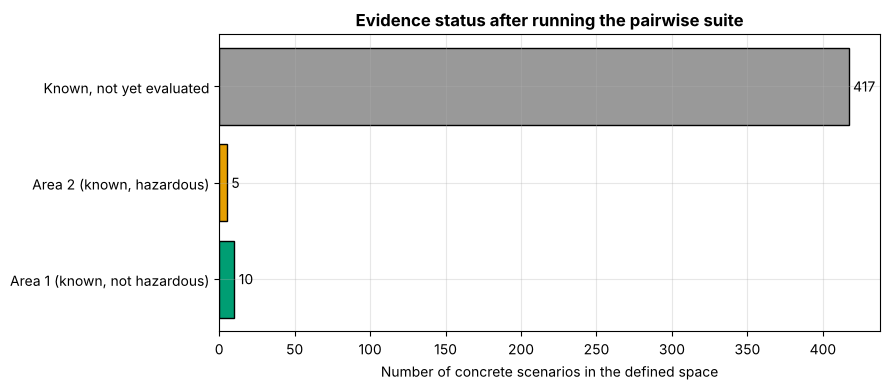

Text summary: Area 1 (known, not hazardous): 10; Area 2 (known, hazardous): 5; Known, not yet evaluated: 417 — Area 3/4 scenarios lie outside the parameterised space and are not represented here.


In [18]:
def classify_scenario(sc, test_results):
    """Place a concrete scenario of the defined space into an ISO 21448 area, based on evaluation evidence.

    test_results: dict mapping scenario key -> 'pass' | 'fail'.
    """
    key = tuple(sorted(sc.items()))
    outcome = test_results.get(key)
    if outcome == 'pass':
        return 'Area 1 (known, not hazardous)'
    if outcome == 'fail':
        return 'Area 2 (known, hazardous)'
    return 'Known, not yet evaluated'

test_results = {tuple(sorted(sc.items())): ('fail' if evaluate(sc)['hazardous'] else 'pass') for sc in pairwise_suite}
uni_df['status'] = [classify_scenario(sc, test_results) for sc in universe]
status_counts = uni_df['status'].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
order = ['Area 1 (known, not hazardous)', 'Area 2 (known, hazardous)', 'Known, not yet evaluated']
colors = [OI['green'], OI['orange'], OI['grey']]
vals = [status_counts.get(o, 0) for o in order]
ax.barh(order, vals, color=colors, edgecolor='black')
for i, v in enumerate(vals):
    ax.text(v + 3, i, str(v), va='center')
ax.set_xlabel('Number of concrete scenarios in the defined space')
ax.set_title('Evidence status after running the pairwise suite', fontweight='bold')
plt.tight_layout(); plt.show()

print("Text summary:", "; ".join(f"{o}: {v}" for o, v in zip(order, vals)),
      "— Area 3/4 scenarios lie outside the parameterised space and are not represented here.")

**Coverage is not risk.** 100 % pairwise coverage says the *chosen* discretisation was explored at *pairwise*
depth. It does not say that the discretisation is fine enough (what happens at 45 km/h?), that the parameters are the
right ones (umbrella?), or how often each scenario occurs. A residual-risk argument therefore combines (i) coverage of
a well-justified scenario space, (ii) search for hazardous regions, and (iii) exposure-weighted statistical evidence —
see [Notebook 04](04_simulation_based_validation.ipynb).

## 8. Executable scenarios: ASAM OpenSCENARIO and tools

- **ASAM OpenSCENARIO XML** (current version 1.4.0, May 2026, as of October 2026; https://www.asam.net/standards/detail/openscenario-xml/)
  describes the dynamic content of a scenario — actors, manoeuvres, triggers — with **parameter declarations**; road
  networks are described in **ASAM OpenDRIVE**. **ASAM OpenSCENARIO DSL** is a domain-specific language for more
  abstract, logical scenarios.
- **esmini** is an open-source player for OpenSCENARIO XML; **CARLA** (with ScenarioRunner) also executes OpenSCENARIO.
- **ASAM OpenODD 1.0.0** (April 2025) describes ODDs in machine-readable form.

The cell below writes our pairwise test set as an OpenSCENARIO-style parameter value set. It is **schematic** —
it shows the idea (one logical scenario file + a list of concrete parameter assignments) and has not been validated
against the ASAM XML schema. No simulator is needed to run this notebook.

In [19]:
def to_parameter_sets(suite, max_sets=3):
    lines = ['<ParameterValueDistribution>',
             '  <ScenarioFile filepath="pedestrian_crossing_logical.xosc"/>',
             '  <Deterministic>',
             '    <DeterministicMultiParameterDistribution>',
             '      <ValueSetDistribution>']
    for sc in suite[:max_sets]:
        lines.append('        <ParameterValueSet>')
        for k, v in sc.items():
            lines.append(f'          <ParameterAssignment parameterRef="{k}" value="{v}"/>')
        lines.append('        </ParameterValueSet>')
    lines += ['        <!-- ... remaining concrete scenarios ... -->',
              '      </ValueSetDistribution>',
              '    </DeterministicMultiParameterDistribution>',
              '  </Deterministic>',
              '</ParameterValueDistribution>']
    return '\n'.join(lines)

print(f"Schematic OpenSCENARIO-style parameter sets (first 3 of {len(pairwise_suite)}):\n")
print(to_parameter_sets(pairwise_suite))

Schematic OpenSCENARIO-style parameter sets (first 3 of 15):

<ParameterValueDistribution>
  <ScenarioFile filepath="pedestrian_crossing_logical.xosc"/>
  <Deterministic>
    <DeterministicMultiParameterDistribution>
      <ValueSetDistribution>
        <ParameterValueSet>
          <ParameterAssignment parameterRef="ego_speed_kmh" value="30"/>
          <ParameterAssignment parameterRef="illumination" value="day"/>
          <ParameterAssignment parameterRef="occlusion" value="none"/>
          <ParameterAssignment parameterRef="ped_motion" value="walk"/>
          <ParameterAssignment parameterRef="pedestrian" value="adult"/>
          <ParameterAssignment parameterRef="precipitation" value="none"/>
          <ParameterAssignment parameterRef="road_surface" value="dry"/>
        </ParameterValueSet>
        <ParameterValueSet>
          <ParameterAssignment parameterRef="ego_speed_kmh" value="30"/>
          <ParameterAssignment parameterRef="illumination" value="dusk"/>
          <P

## 9. Validation strategy: combining test environments

| Method | Purpose | Typical scale (indicative) |
|---|---|---|
| **Simulation** (MiL/SiL/HiL) | Broad exploration, rare and dangerous scenarios, parameter sweeps | 10⁶–10⁹ km equivalent or 10⁴–10⁷ concrete runs |
| **Proving ground** | Physical sensors and vehicle in controlled scenarios; correlation of simulation | 10²–10⁴ scenario runs |
| **Public road / field operational test** | Real exposure, discovery of the unexpected | 10⁵–10⁷ km |
| **Analysis** (HARA, STPA, FMEA, formal methods) | Identification of hazards, insufficiencies and triggering conditions | Spans all of the above |

SOTIF validation aims to show that the residual risk from **known (Area 2)** and **unknown (Area 3)** hazardous
scenarios meets the acceptance criteria.

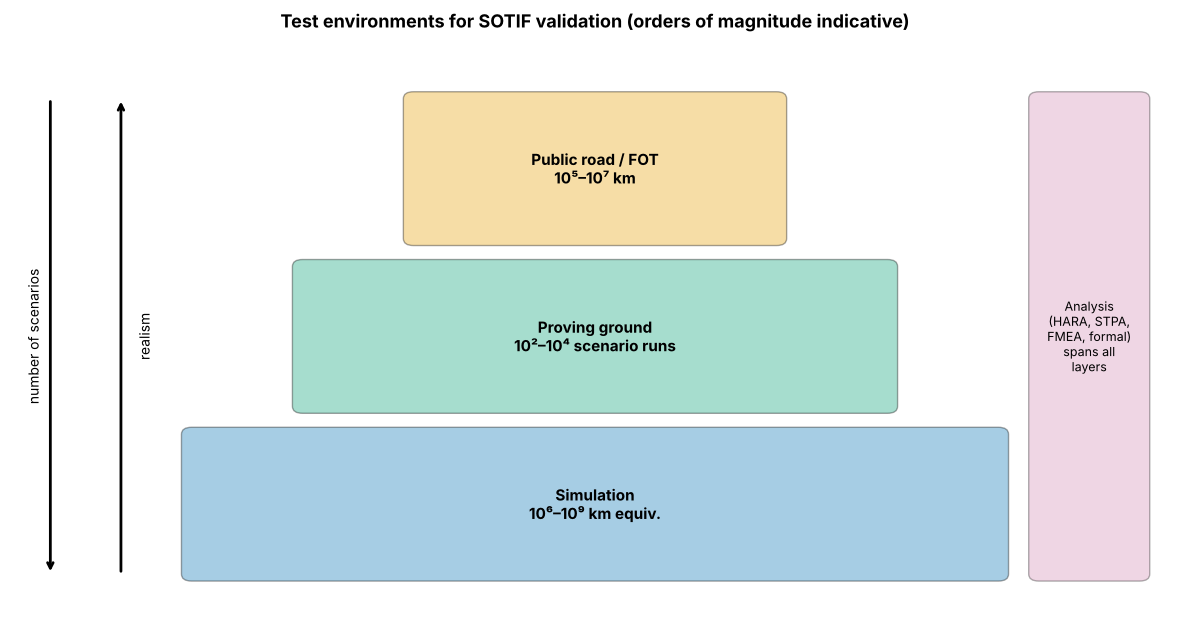

In [20]:
def visualize_validation_layers():
    """Test environments (pyramid) with analysis as a cross-cutting activity."""
    fig, ax = plt.subplots(figsize=(12, 6.5))
    layers = [('Simulation\n10⁶–10⁹ km equiv.', 0.80, OI['blue']),
              ('Proving ground\n10²–10⁴ scenario runs', 0.58, OI['green']),
              ('Public road / FOT\n10⁵–10⁷ km', 0.36, OI['orange'])]
    y = 0.08
    for label, width, col in layers:
        ax.add_patch(FancyBboxPatch((0.5 - width / 2, y), width, 0.2, boxstyle='round,pad=0.01',
                                    facecolor=col, alpha=0.35, edgecolor='black'))
        ax.text(0.5, y + 0.1, label, ha='center', va='center', fontsize=11, fontweight='bold')
        y += 0.24
    ax.add_patch(FancyBboxPatch((0.94, 0.08), 0.1, 0.68, boxstyle='round,pad=0.01',
                                facecolor=OI['purple'], alpha=0.3, edgecolor='black'))
    ax.text(0.99, 0.42, 'Analysis\n(HARA, STPA,\nFMEA, formal)\nspans all\nlayers', ha='center', va='center', fontsize=9)
    ax.annotate('', xy=(-0.04, 0.08), xytext=(-0.04, 0.76), arrowprops=dict(arrowstyle='->', lw=2))
    ax.text(-0.065, 0.42, 'number of scenarios', rotation=90, va='center', fontsize=10)
    ax.annotate('', xy=(0.03, 0.76), xytext=(0.03, 0.08), arrowprops=dict(arrowstyle='->', lw=2))
    ax.text(0.045, 0.42, 'realism', rotation=90, va='center', fontsize=10)
    ax.set_xlim(-0.08, 1.08); ax.set_ylim(0, 0.85); ax.axis('off')
    ax.set_title('Test environments for SOTIF validation (orders of magnitude indicative)', fontsize=13,
                 fontweight='bold')
    plt.tight_layout(); plt.show()

visualize_validation_layers()

## 10. Exercise: Lane Keeping Assist (LKA)

1. List at least five triggering conditions for an LKA, grouped by 6-layer model layer.
2. List the functional insufficiencies they activate; mark each as *specification* or *performance*.
3. Define a logical scenario (4–6 discretised parameters, at least one physical constraint).
4. Build a pairwise test set with `greedy_pairwise` and report 2- and 3-wise coverage.
5. Which hazardous scenarios could lie *outside* your parameterisation (Area 3 candidates)?

**Real-data extension (Section 5).** Add visibilities 200 m and 60 m to `VISIBILITIES` and re-run Sections 5.2–5.4: does the bracket around the fog boundary narrow? Then replace the uniform atmospheric light by $A = 0.6$ and report how sensitive the boundary is to this modelling assumption — a question an assessor will ask about any synthetic-condition evidence.

The starter code runs as it is; fill in the lists and domains.

In [21]:
# Exercise starter: Lane Keeping Assist
lka_triggering_conditions = {
    # 'L1 Road network': ['Faded lane markings', ...],
    # 'L5 Environment': ['Low sun on wet road', ...],
}
lka_insufficiencies = [
    # {'FI-ID': 'FI-L1', 'type': 'Performance', 'description': 'Lane detector misses low-contrast markings',
    #  'activated_by': ['Faded lane markings']},
]
lka_domains = {
    # 'curve_radius_m': [250, 500, 1000],
    # 'marking_quality': ['good', 'faded', 'missing'],
    # 'illumination': ['day', 'low_sun', 'night'],
    # 'road_surface': ['dry', 'wet'],
}

n_tc = sum(len(v) for v in lka_triggering_conditions.values())
print(f"Triggering conditions: {n_tc}; functional insufficiencies: {len(lka_insufficiencies)}")
if len(lka_domains) >= 2:
    lka_universe = full_factorial(lka_domains)
    lka_suite = greedy_pairwise(lka_universe, lka_domains)
    print(f"Pairwise suite: {len(lka_suite)} of {len(lka_universe)} scenarios; "
          f"3-wise coverage {nwise_coverage(lka_domains, lka_suite, min(3, len(lka_domains)))['coverage']:.0%}")
else:
    print("Define at least two parameters in lka_domains to build a pairwise suite.")

Triggering conditions: 0; functional insufficiencies: 0
Define at least two parameters in lka_domains to build a pairwise suite.


## In industry

**Work product.** The *triggering-condition analysis* of ISO 21448 (clauses 6–7), usually a table or database per
function, linked to the hazard analysis and to the verification and validation plan (clauses 9–10). The measured
boundaries of Section 5 enter it as **evidence for performance insufficiencies**; the derived ODD restrictions go
into the function specification (clause 5) and the ODD description (ISO 34503).

**Who produces it.** The SOTIF / safety engineer owns the analysis; perception engineers run the measurements on the
released software version; the function owner decides on measures (functional modification vs ODD restriction); the
V&V team turns each row into test cases. Scenario parameters are exchanged in ASAM OpenSCENARIO / OpenODD form.

**What reviewers and assessors check.**

- [ ] Catalogue structured (6-layer model or ISO 34503 taxonomy), E/E faults and attacks kept out, misuse included
- [ ] Every triggering condition linked to a functional insufficiency and to hazardous behaviour in the HARA
- [ ] Parameter ranges stated with **uncertainty**; sample sizes and confidence intervals reported
- [ ] Measurements on the **released** sensor/software configuration; synthetic conditions validated against real data
- [ ] Measures traced to requirements; ODD restrictions monitorable at runtime (visibility, illumination, blockage)
- [ ] Combinations of triggering conditions analysed (fog *and* night), not only single factors
- [ ] Coverage arguments separated from residual-risk arguments (Areas 2 and 3)

## Key takeaways

- A triggering-condition catalogue describes **the world**; structure it with the **6-layer model** and keep sensor
  exposure and driver misuse as separate groups. E/E faults and attacks belong to other standards.
- Functional insufficiencies are **specification** or **performance** insufficiencies of the system; training-data
  coverage gaps are performance insufficiencies.
- A performance insufficiency is **measured**: real component, real data, one condition varied, recall with confidence
  intervals against a derived requirement. The result is a **boundary bracket**, which becomes an ODD restriction or a
  functional modification.
- Synthetic conditions on real data (Koschmieder fog from LiDAR depth, noise models) are useful evidence only with a
  stated credibility argument.
- Scenarios are described at **functional, logical and concrete** level; the **ODD** (ISO 34503: scenery,
  environmental conditions, dynamic elements) bounds where the function may operate.
- **ISO 34502** frames scenario-based evaluation; **ASAM OpenSCENARIO/OpenDRIVE/OpenODD** make scenarios and ODDs executable.
- **n-wise coverage** of a discretised space is measurable and efficient to achieve, but it is not a measure of
  residual risk; higher-order interactions and Area 3 lie beyond it.

## Self-assessment

1. What is a scenario in the context of SOTIF, and how does it differ from an ODD?
2. Describe the three levels of scenario abstraction (functional, logical, concrete).
3. Is "out-of-distribution input" a triggering condition? Explain.
4. How can combinatorial testing reduce the number of scenarios to evaluate, and what can it miss?
5. Why can a scenario that has not been tested not be placed in Area 3 by a script?
6. Why is it impossible to test all possible driving scenarios exhaustively?
7. In Section 5.3 a visibility gives recall 0.62 with a 95 % interval [0.54, 0.70] against a requirement of 0.65. What do
   you write in the triggering-condition analysis?
8. Why does fog reduce the recall for distant pedestrians more than for near ones, and how does this lead to a
   speed restriction rather than a simple on/off ODD boundary?

<details>
<summary>Answers</summary>

1. A scenario is a temporal sequence of scenes with the actions and events of the participants. The ODD describes the
   operating conditions under which the function is designed to work; scenarios happen inside, outside or across it.
2. Functional: linguistic description; logical: parameters with ranges or distributions; concrete: one fixed value
   per parameter, executable.
3. No. It describes a gap in the system's training-data coverage, i.e. a performance insufficiency. The triggering
   condition is the scenario condition (e.g. a wheelchair user) that the gap makes the system unable to handle.
4. n-wise test sets cover every combination of values of any n parameters with far fewer tests than the full
   factorial (here a handful instead of hundreds). They can miss failures that need more than n interacting
   conditions, values between grid points, and parameters that were never modelled.
5. Areas 3 and 4 are *unknown* scenarios — not part of anyone's list. A scenario in the defined space is known; if not
   yet evaluated it is "known, not yet evaluated", not Area 3.
6. The parameter space is continuous and high-dimensional, and the set of relevant parameters itself is open; even a
   coarse discretisation explodes combinatorially, and real-world exposure to rare combinations is tiny.
7. *Inconclusive*: the data neither demonstrate nor refute the requirement. Record the condition as a candidate
   triggering condition, collect more pedestrians at that visibility (or nearby ones to narrow the bracket), and do
   not use it to claim compliance.
8. Transmission $t = e^{-\beta d}$ falls with distance, so contrast is lost first far away. The detector therefore keeps
   working at short range; the function remains acceptable if it only needs that range — i.e. at lower speed, whose
   stopping distance fits inside it.
</details>

## References

- ISO 21448:2022 *Road vehicles — Safety of the intended functionality*.
- ISO 34502:2022 *Road vehicles — Test scenarios for automated driving systems — Scenario based safety evaluation framework*.
- ISO 34503:2023 *Road vehicles — Test scenarios for automated driving systems — Specification for operational design domain*.
- SAE J3016 (2021) *Taxonomy and Definitions for Terms Related to Driving Automation Systems for On-Road Motor Vehicles*.
- Menzel, T., Bagschik, G., Maurer, M. (2018). Scenarios for Development, Test and Validation of Automated Vehicles. *IEEE IV 2018*, 1821–1827. https://doi.org/10.1109/IVS.2018.8500406
- Scholtes, M., Westhofen, L., Turner, L. R., et al. (2021). 6-Layer Model for a Structured Description and Categorization of Urban Traffic and Environment. *IEEE Access* 9, 59131–59147. https://doi.org/10.1109/ACCESS.2021.3072739
- Riedmaier, S., Ponn, T., Ludwig, D., Schick, B., Diermeyer, F. (2020). Survey on Scenario-Based Safety Assessment of Automated Vehicles. *IEEE Access* 8, 87456–87477. https://doi.org/10.1109/ACCESS.2020.2993730
- Hou, Z., Liu, D., Yang, Y., Liu, H. (2024). Assessing Unknown Hazards for SOTIF Based on Twin Scenarios Empowered Autonomous Driving. *IEEE Internet of Things Journal* 11, 32631–32644. https://doi.org/10.1109/JIOT.2024.3424550 — an example of generating variations of known scenarios to search for unknown hazards.
- Patel, M., Jung, R., Khatun, M. (2025). A Systematic Literature Review on Safety of the Intended Functionality for Automated Driving Systems. SAE Technical Paper 2025-01-5030. https://doi.org/10.4271/2025-01-5030
- Koschmieder, H. (1924). Theorie der horizontalen Sichtweite. *Beiträge zur Physik der freien Atmosphäre* 12, 33–53.
- Sakaridis, C., Dai, D., Van Gool, L. (2018). Semantic Foggy Scene Understanding with Synthetic Data. *International Journal of Computer Vision* 126, 973–992. https://doi.org/10.1007/s11263-018-1072-8
- Hahner, M., Sakaridis, C., Dai, D., Van Gool, L. (2021). Fog Simulation on Real LiDAR Point Clouds for 3D Object Detection in Adverse Weather. *IEEE/CVF ICCV 2021*, 15263–15272. https://doi.org/10.1109/ICCV48922.2021.01500
- Bijelic, M., Gruber, T., Mannan, F., et al. (2020). Seeing Through Fog Without Seeing Fog: Deep Multimodal Sensor Fusion in Unseen Adverse Weather. *IEEE/CVF CVPR 2020*, 11679–11689. https://doi.org/10.1109/CVPR42600.2020.01170
- Foi, A., Trimeche, M., Katkovnik, V., Egiazarian, K. (2008). Practical Poissonian-Gaussian Noise Modeling and Fitting for Single-Image Raw-Data. *IEEE Transactions on Image Processing* 17(10), 1737–1754. https://doi.org/10.1109/TIP.2008.2001399
- Geiger, A., Lenz, P., Urtasun, R. (2012). Are we ready for autonomous driving? The KITTI vision benchmark suite. *IEEE CVPR 2012*, 3354–3361. https://doi.org/10.1109/CVPR.2012.6248074
- Ren, S., He, K., Girshick, R., Sun, J. (2017). Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks. *IEEE TPAMI* 39(6), 1137–1149. https://doi.org/10.1109/TPAMI.2016.2577031 · Howard, A., et al. (2019). Searching for MobileNetV3. *IEEE/CVF ICCV 2019*, 1314–1324. https://doi.org/10.1109/ICCV.2019.00140
- Velodyne HDL-64E user manual and specification (range 50 m for pavement at ≈ 10 % reflectivity, 120 m for cars and foliage at ≈ 80 %).
- Straßenverkehrs-Ordnung (StVO), § 3 (1): https://www.gesetze-im-internet.de/stvo_2013/__3.html
- Patel, M., Jung, R. (2026). Uncertainty Evaluation to Support Safety of the Intended Functionality Analysis for Identifying Performance Insufficiencies in ML-Based LiDAR Object Detection. *VEHITS 2026*. https://doi.org/10.5220/0014967200004030
- Patel, M., Jung, R. (2024). Simulation-Based Performance Evaluation of 3D Object Detection Methods with Deep Learning for a LiDAR Point Cloud Dataset in a SOTIF-related Use Case. *VEHITS 2024*. https://doi.org/10.5220/0012707300003702
- ASAM OpenSCENARIO XML: https://www.asam.net/standards/detail/openscenario-xml/ · ASAM OpenODD: https://www.asam.net/standards/detail/openodd/
- NIST Combinatorial Testing (ACTS): https://csrc.nist.gov/projects/automated-combinatorial-testing-for-software

---
**Navigation:** ← [prev: SOTIF fundamentals](01_sotif_fundamentals.ipynb) · [Module index](README.md) · [next: OOD monitoring as a safety measure](03_ood_monitoring_as_safety_measure.ipynb) →